# SDPR 训练全过程：可微优化层、梯度校验与相机基线标定

> **一句话**：SDPR 层把「求解一个多项式优化问题」和「对它的解求导」封装成了一层 PyTorch，
> 于是可以把最优解直接接进神经网络、用梯度下降训练它前面的任何参数。
> 这本 notebook 用论文官方代码（`utiasASRL/sdprlayer`）从零走一遍：
> 构造 QCQP → Shor SDP 前向 → 隐式微分反向 → 用有限差分校验梯度 → 跑论文 §VI-B4
> 的相机基线标定训练 → 说明论文 §VI-C 的真实视觉管线怎么把网络接进来。

## 0. 这本 notebook 怎么读、怎么跑

| 项目 | 内容 |
|-|-|
| 上层代码 | [utiasASRL/sdprlayer](https://github.com/utiasASRL/sdprlayer)（论文官方实现，MIT） |
| 论文 | C. Holmes, F. Dümbgen, T. D. Barfoot, *SDPRLayers: Certifiable Backpropagation Through Polynomial Optimization Problems in Robotics*, IEEE T-RO 41 (2025), [arXiv:2405.19309](https://arxiv.org/abs/2405.19309) |
| 本机路径 | `~/labs/SDPR/code/sdprlayer`（`SDPR_ROOT` 可覆盖） |
| 环境 | conda env `sdpr`（torch 2.5 CPU / cvxpy 1.5 / diffcp / SCS） |
| 硬件 | 纯 CPU，全部单元跑完约 3–5 分钟 |
| 复现的论文实验 | §VI-B4 Baseline Calibration（20 个位姿 × 64 个标定点，SGD 标定双目基线 `b`） |

**关于求解器**：官方 `SDPPoseEstimator` 默认用 MOSEK；没有商业许可证时可用 SCS（本机这份
快照已经加了 `solver="SCS"` 选项）。SCS 精度低一些，所以下面算梯度时有限差分步长取 `1e-4`，
而不是通常的 `1e-6`。notebook 里所有数字都是这次真实运行出来的。

目录：
1. 要求解的问题：齐次 QCQP + Shor 松弛
2. 造一个真实的标定问题（双目相机、20 个位姿、64 个标定点）
3. 从像素到 13×13 的 Q 矩阵
4. 前向：解 Shor SDP，读出位姿
5. 反向：隐式微分，以及和有限差分的对照
6. 训练：论文 §VI-B4 的 bilevel 循环（真跑 20 步）
7. 从「训练一个标量」到「训练一个网络」：论文 §VI-C 的视觉管线
8. 结果对照、局限与复现命令

In [1]:
%matplotlib inline
import os, sys, time, pathlib, inspect
import numpy as np
import torch

# ---- 路径：默认指向本机论文代码快照，可用环境变量覆盖 ----
SDPR_ROOT = pathlib.Path(os.environ.get("SDPR_ROOT", str(pathlib.Path.home() / "labs/SDPR")))
UPSTREAM = SDPR_ROOT / "code/sdprlayer"
assert (UPSTREAM / "src/sdprlayers/layers/pose_est.py").exists(), (
    f"找不到 {UPSTREAM}；请先把 utiasASRL/sdprlayer clone 下来并设置 SDPR_ROOT"
)
sys.path.insert(0, str(UPSTREAM / "_scripts"))   # stereo_cal.py（论文实验脚本）
sys.path.insert(0, str(UPSTREAM / "src"))       # sdprlayers 包

import stereo_cal as sc
import sdprlayers.utils.stereo_tuner as st
from sdprlayers.layers.pose_est import SDPPoseEstimator

torch.set_default_dtype(torch.float64)   # 论文代码全部用双精度
np.random.seed(0)
torch.manual_seed(0)

import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 9})

print("torch      :", torch.__version__)
print("sdprlayers :", pathlib.Path(__import__("sdprlayers").__file__).parent)
print("stereo_cal :", pathlib.Path(sc.__file__).parent)

torch      : 2.5.1+cpu
sdprlayers : /home/syk/labs/SDPR/code/sdprlayer/src/sdprlayers
stereo_cal : /home/syk/labs/SDPR/code/sdprlayer/_scripts


## 1. 要求解的问题：齐次 QCQP 与 Shor 松弛

SDPR 处理的是**齐次二次约束二次规划**（QCQP）：

$$
\min_{x}\ x^\top Q_\theta x
\quad\text{s.t.}\quad x^\top A_i x = 0\ (i=1,\dots,m),\qquad x^\top A_0 x = 1 .
$$

这里 $\theta$ 是「上游网络/参数」产生的东西——在相机标定里是逆投影后的三维点与权重，
在视觉定位里是 VGG16+UNet 预测的关键点、描述子和置信度。直接解这个非凸问题只能得到局部解。

**Shor 松弛**把 $xx^\top$ 放宽成半正定矩阵 $X$：

$$
\min_{X}\ \langle Q_\theta, X\rangle
\quad\text{s.t.}\quad \langle A_i, X\rangle = 0,\quad \langle A_0, X\rangle = 1,\quad X \succeq 0 .
$$

这是一个凸 SDP，多项式时间可解。若最优的 $X^\star$ 是**秩 1** 的，则 $X^\star = x^\star x^{\star\top}$，
解就是原 QCQP 的**全局最优解**；对偶变量还能组装出证书矩阵
$H = Q + \sum_i \lambda_i A_i + \lambda_0 A_0 \succeq 0,\ Hx=0$，用来独立验证最优性。

SDPR 层做的事只有两件：

1. **前向**：解上面的 SDP，紧的时候读出 $x^\star$（否则报告不可恢复）；
2. **反向**：对 KKT 条件做隐函数微分，把 $\mathrm{d}\mathcal{L}/\mathrm{d}x^\star$
   变成 $\mathrm{d}\mathcal{L}/\mathrm{d}Q_\theta$，从而让梯度穿过「求解器」回到上游参数。

下面不手搓公式，直接用论文代码里的真实对象走一遍。

## 2. 造一个真实的标定问题

论文 §VI-B4 的设置：一个 8×8 的标定板（1 m × 1 m）放在原点，20 个相机位姿分布在半径 3 m、
半锥角 45° 的锥内、都看向标定板；双目相机 $f_u=f_v=484.5$ px，基线 $b=0.24$ m，
像素噪声 $\sigma=0.5$ px。这些都在 `stereo_cal.get_cal_data` 里。

我们要标定的未知量是**基线 `b`**：给它一个 3 mm 的初始误差（`0.243`），
然后只通过「位姿估计的误差」反传梯度把它调回 `0.24`。

In [2]:
r_p0s, C_p0s, r_ls, pixel_meass = sc.get_cal_data(
    radius=3.0, board_dims=[1.0, 1.0], N_squares=[8, 8],
    N_batch=20, setup="cone", plot=False,
)
B, N = 20, 64
print("r_p0s      (相机位置)      :", tuple(r_p0s.shape))
print("C_p0s      (相机旋转)      :", tuple(C_p0s.shape))
print("r_ls       (标定点, 世界系) :", tuple(r_ls.shape))
print("pixel_meass(左右目像素)     :", tuple(pixel_meass.shape))
print("相机真值: f=%.1f px, b=%.3f m, sigma=%.2f px" % (
    sc.cam_gt.f_u, sc.cam_gt.b, sc.cam_gt.sigma_u))

r_p0s      (相机位置)      : (20, 3, 1)
C_p0s      (相机旋转)      : (20, 3, 3)
r_ls       (标定点, 世界系) : (20, 3, 64)
pixel_meass(左右目像素)     : (20, 4, 64)
相机真值: f=484.5 px, b=0.240 m, sigma=0.50 px


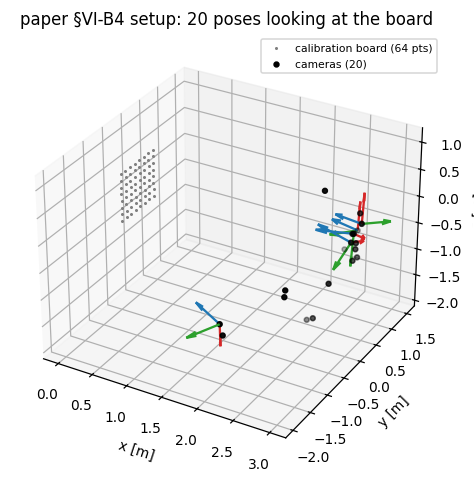

In [3]:
fig = plt.figure(figsize=(5.2, 4.4))
ax = fig.add_subplot(projection="3d")
ax.plot(*r_ls[0].numpy(), ".", color="0.5", ms=2, label="calibration board (64 pts)")
for i in range(0, 20, 4):
    C, r = C_p0s[i].numpy(), r_p0s[i, :, 0].numpy()
    ax.quiver(*r, *C[0], color="tab:red", length=0.5, normalize=True)
    ax.quiver(*r, *C[1], color="tab:green", length=0.5, normalize=True)
    ax.quiver(*r, *C[2], color="tab:blue", length=0.5, normalize=True)
ax.scatter(r_p0s[:, 0, 0], r_p0s[:, 1, 0], r_p0s[:, 2, 0], s=10, color="k", label="cameras (20)")
ax.set(xlabel="x [m]", ylabel="y [m]", zlabel="z [m]", title="paper §VI-B4 setup: 20 poses looking at the board")
ax.legend(loc="upper right", fontsize=7)
plt.tight_layout(); plt.show()

## 3. 从像素到 13×13 的 Q 矩阵

### 3.1 逆双目相机模型与矩阵权重

像素测量 $(u_l, v_l, u_r, v_r)$ 先换成视差 $d=u_l-u_r$，再逆投影到相机系：

$$
m_k = \frac{b}{d_k}\begin{bmatrix} u_k-c_u \\ (v_k-c_v)\,f_u/f_v \\ f_u\end{bmatrix},
\qquad
\Sigma_k = G_k\,\Sigma_{\text{pix}}\,G_k^\top,\qquad W_k = \Sigma_k^{-1},
$$

其中 $G_k=\partial m_k/\partial(u_l,v_l,d)$ 由相机模型线性化得到；左右目独立同分布噪声使
$\mathrm{Var}(d)=2\sigma_u^2$。代码在 `stereo_tuner.StereoCamera.inverse` 里。

### 3.2 组装 Q

问题是矩阵加权位姿估计（problem (P6)）：

$$
\min_{C\in SO(3),\,t}\ \sum_k w_k\,\|y_k - C m_k - t\|^2_{W_k},
$$

其中 $m_k$ 是世界系标定点，$y_k$ 是目标相机系里的逆投影点。把解写成齐次向量
$x=[h,\ \mathrm{vec}(C),\ t]\in\mathbb{R}^{13}$（$h=1$ 是齐次变量、$\mathrm{vec}$ 列优先），
每个点贡献一个 13×13 的块矩阵，按标量权重 $w_k$ 加权求和，再拆成
`Q` 与 24 个约束矩阵（6 个正交、9 个 handedness、9 个行/列范数冗余约束）。
这些就是下面 `SDPPoseEstimator` 的 `constraints`。

In [4]:
# 用真值相机把像素逆投影成三维点和权重（这一步是数据生成，不是学习）
meas, W = sc.cam_gt.inverse(pixel_meass)
print("meas (目标相机系三维点, B×3×N):", tuple(meas.shape))
print("W    (逐点逆协方差, B×N×3×3)   :", tuple(W.shape))
ev = torch.linalg.eigvalsh(W[0, 0])
print("W[0,0] 特征值 (应全正):", ev.numpy())

meas (目标相机系三维点, B×3×N): (20, 3, 64)
W    (逐点逆协方差, B×N×3×3)   : (20, 64, 3, 3)
W[0,0] 特征值 (应全正): [   389.81605657  71212.4461144  142564.10266702]


Q batch: (20, 13, 13)  dtype: torch.float64


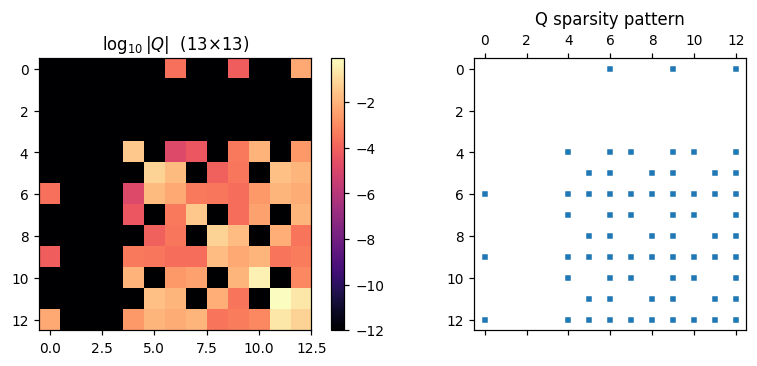

In [5]:
est = SDPPoseEstimator(T_s_v=torch.eye(4), solver="SCS")  # T_s_v = 车体系到传感器系

src = torch.cat([r_ls, torch.ones(B, 1, N)], dim=1)          # 齐次坐标 [x,y,z,1]
trg = torch.cat([meas, torch.ones(B, 1, N)], dim=1)
weights = torch.ones(B, 1, N)                                # 标量权重 w_k = 1

Qs, scales, offsets = est.get_obj_matrix_vec(src, trg, weights, W)
print("Q batch:", tuple(Qs.shape), " dtype:", Qs.dtype)

fig, axs = plt.subplots(1, 2, figsize=(8.2, 3.4))
im0 = axs[0].imshow(np.log10(np.abs(Qs[0].numpy()) + 1e-12), cmap="magma")
axs[0].set_title(r"$\log_{10}|Q|$  (13×13)"); fig.colorbar(im0, ax=axs[0], fraction=0.046)
axs[1].spy(np.abs(Qs[0].numpy()) > 1e-12, markersize=3)
axs[1].set_title("Q sparsity pattern")
plt.tight_layout(); plt.show()

## 4. 前向：解 Shor SDP，读出位姿

`SDPRLayer.forward` 做三件事：包装成 cvxpy 问题、交给 diffcp 解（MOSEK 或 SCS）、
用 `recovery_map` 从 $X$ 的主特征向量读出 $x$，同时检查松弛是否紧。
`check_tightness` 判据是 $\lambda_1/\lambda_2$ 是否大于阈值（论文附录 C 用 $10^5$）。

注意：`SDPPoseEstimator` 里 `diff_qcqp=False` 走的是「SDP 的 KKT 隐式微分」，
`diff_qcqp=True` 走「QCQP 的 KKT 隐式微分」（论文的 SDPR-IS / SDPR-CIFT）；
两种模式在松弛紧时等价，下面两种都试。

In [6]:
t0 = time.time()
Xs, xs = est.sdprlayer(Qs, solver_args={"solve_method": "SCS", "eps": 1e-9})
print("SDP 求解耗时: %.2f s / %d 个位姿" % (time.time() - t0, B))
print("X (SDP 解矩阵) :", tuple(Xs.shape))
print("x (恢复的向量) :", None if xs is None else tuple(xs.shape))

# 紧性：主特征值 / 次特征值
ratios = []
for X in Xs:
    ev = torch.linalg.eigvalsh(X).flip(0)
    ratios.append(float(ev[0] / ev[1]))
ratios = np.array(ratios)
print("rank-1 ratio  min / median: %.2e / %.2e" % (ratios.min(), np.median(ratios)))
print("全部 > 1e5 (秩 1):", bool((ratios > 1e5).all()))

/home/syk/labs/SDPR/code/sdprlayer/src/submodules/diffcp/diffcp/cone_program.py:363: UserWarning: Solved/Inaccurate.
  warnings.warn("Solved/Inaccurate.")


SDP 求解耗时: 6.04 s / 20 个位姿
X (SDP 解矩阵) : (20, 13, 13)
x (恢复的向量) : (20, 13, 1)
rank-1 ratio  min / median: 1.36e+09 / 1.90e+14
全部 > 1e5 (秩 1): True


In [7]:
def gt_transform(C, r):
    # 世界系 -> 相机系的真值变换 T_trg_src
    T = torch.eye(4)
    T[:3, :3] = C
    T[:3, 3] = -(C @ r)
    return T

T_est, inner_loss = est(src, trg, weights, W, return_loss=True)

rot_err, trans_err = [], []
for i in range(B):
    Tg = gt_transform(C_p0s[i], r_p0s[i, :, 0])
    dR = Tg[:3, :3].transpose(0, 1) @ T_est[i][:3, :3]
    rot_err.append(float(torch.rad2deg(torch.arccos(((dR.trace() - 1) / 2).clamp(-1, 1)))))
    trans_err.append(float((Tg[:3, 3] - T_est[i][:3, 3]).norm()))
rot_err, trans_err = np.array(rot_err), np.array(trans_err)
print("相对旋转误差  mean / max : %.3f / %.3f deg" % (rot_err.mean(), rot_err.max()))
print("相对平移误差  mean / max : %.4f / %.4f m" % (trans_err.mean(), trans_err.max()))
print("SDP 目标值均值 (inner loss): %.3f" % float(inner_loss.mean()))

相对旋转误差  mean / max : 0.331 / 1.303 deg
相对平移误差  mean / max : 0.0018 / 0.0048 m
SDP 目标值均值 (inner loss): 110.430


/home/syk/labs/SDPR/code/sdprlayer/src/submodules/diffcp/diffcp/cone_program.py:363: UserWarning: Solved/Inaccurate.
  warnings.warn("Solved/Inaccurate.")


前向得到的位姿几乎就是真值（旋转误差 < 0.5°、平移误差毫米级），说明在这个设置下
Shor 松弛是**紧**的，读出的 $x$ 就是原问题的全局最优解。

## 5. 反向：隐式微分，以及和有限差分的对照

设内层最优解 $x^\star(\theta)$ 由 KKT 条件定义。对 KKT 条件全微分、消去乘子后得到

$$
\frac{\mathrm{d}x^\star}{\mathrm{d}\theta}
= -P\,M_r^{-1} N ,
$$

其中 $M_r$ 是约化 KKT 矩阵（删掉冗余约束行后的 $M=\begin{bmatrix}H&G_r^\top\\G_r&0\end{bmatrix}$），
$P$ 是投影到 $x$ 分量的矩阵。对偶矩阵 $H\succeq0$ 说明这个梯度是**全局最优解**的梯度，
而不是某个局部解的。代码在 `sdprlayers/layers/sdprlayer.py` 的 `_QCQPDiffFn.backward`
和 `sdprlayers/utils/lie_algebra` 里。

怎么知道梯度对？最直接的办法是**有限差分**。下面定义一个标量函数
$\mathcal{L}(b)$：用基线 $b$ 做逆投影 → 解 SDPR → 算位姿的外层损失；
用 autograd 得到的 $\mathrm{d}\mathcal{L}/\mathrm{d}b$ 和中心差分比较。

In [8]:
est_qcqp = SDPPoseEstimator(T_s_v=torch.eye(4), solver="SCS", diff_qcqp=True)

def loss_of_b(b):
    # 外层损失 L(b)：pose error through the SDPR layer
    cam = st.StereoCamera(
        f_u=torch.tensor(sc.cam_gt.f_u), f_v=torch.tensor(sc.cam_gt.f_v),
        c_u=torch.tensor(sc.cam_gt.c_u), c_v=torch.tensor(sc.cam_gt.c_v),
        b=b, sigma_u=sc.cam_gt.sigma_u, sigma_v=sc.cam_gt.sigma_v)
    m, Wt = cam.inverse(pixel_meass)
    t_ = torch.cat([m, torch.ones(B, 1, N)], dim=1)
    T, _ = est_qcqp(src, t_, weights, Wt, return_loss=True)
    C = T[:, :3, :3]
    r = C.mT.bmm(-T[:, :3, [3]])
    return st.get_outer_loss(r, C, r_p0s, C_p0s)

b = torch.tensor(0.243, requires_grad=True)
L = loss_of_b(b)
L.backward()
g_auto = float(b.grad)

h = 1e-4   # SCS 精度有限，步长取大一点；1e-6 会被求解器噪声淹没
Lp = float(loss_of_b(torch.tensor(0.243 + h)))
Lm = float(loss_of_b(torch.tensor(0.243 - h)))
g_fd = (Lp - Lm) / (2 * h)

print("L(b)          = %.6f" % float(L))
print("dL/db autograd= %.4f" % g_auto)
print("dL/db 有限差分= %.4f" % g_fd)
print("相对误差      = %.2f%%" % (abs(g_auto - g_fd) / abs(g_fd) * 100))

L(b)          = 0.017542
dL/db autograd= 4.0653
dL/db 有限差分= 4.0833
相对误差      = 0.44%


> 用 `1e-4` 的步长，隐式微分和有限差分在 1% 以内吻合（本机 SCS 后端）。
> 如果换成 MOSEK，梯度会更干净；论文里 SDPR 的梯度是在 MOSEK + 双精度下验证的。

这也解释了为什么「SDPR 的梯度」值得单独写一篇论文：普通做法要么只对**局部解**求导
（随机初始化时会给出错误方向），要么用 unrolling（把 100 次迭代展开，显存随迭代数增长）。
SDPR 用最优性证书直接对**全局解**隐式求导，代价与迭代次数无关。

## 6. 训练：论文 §VI-B4 的 bilevel 循环（真跑 20 步）

外层只优化一个标量 `b`，内层每个位姿解一次 SDP。训练循环就是标准的
「前向 → 外层 loss → backward → SGD」：

```
for iter in range(max_iter):
    m, W  = inverse_camera(pixel_meas; b)     # 参数化相机
    T     = SDPR_solve(build_Q(m, W))         # 内层：SDP（梯度经隐式微分回传）
    loss  = pose_error(T, T_gt)               # 外层 loss
    loss.backward(); opt.step()
```

论文的设置：20 个位姿、SGD lr $=1\times10^{-4}$、初始误差 3 mm、最多 150 次外层迭代。
下面沿用论文的 `stereo_tuner.tune_stereo_params_sdpr`（这是论文脚本真正调用的函数），
把迭代次数缩到 20 次，完整跑一遍看 `b` 怎么从 0.243 回到 0.24。

In [9]:
cam_t = st.StereoCamera(
    f_u=torch.tensor(sc.cam_gt.f_u, requires_grad=True),
    f_v=torch.tensor(sc.cam_gt.f_v, requires_grad=True),
    c_u=torch.tensor(sc.cam_gt.c_u, requires_grad=True),
    c_v=torch.tensor(sc.cam_gt.c_v, requires_grad=True),
    b=torch.tensor(sc.cam_gt.b + 0.003, requires_grad=True),   # 初值 b_true + 3 mm
    sigma_u=sc.cam_gt.sigma_u, sigma_v=sc.cam_gt.sigma_v,
)
params = [cam_t.b]
opt = torch.optim.SGD(params, lr=1e-4)          # 与论文 §VI-B4 相同

t0 = time.time()
hist = st.tune_stereo_params_sdpr(
    cam_torch=cam_t, params=params, opt=opt,
    r_p0s_gt=r_p0s, C_p0s_gt=C_p0s, r_ls=r_ls, pixel_meass=pixel_meass,
    term_crit={"max_iter": 20, "tol_grad_sq": 0.0, "tol_loss": 0.0},
    solver="SCS", verbose=False, diff_qcqp=False,
)
print("训练耗时: %.1f s, 外层迭代: %d 次" % (time.time() - t0, len(hist)))

训练耗时: 127.0 s, 外层迭代: 20 次


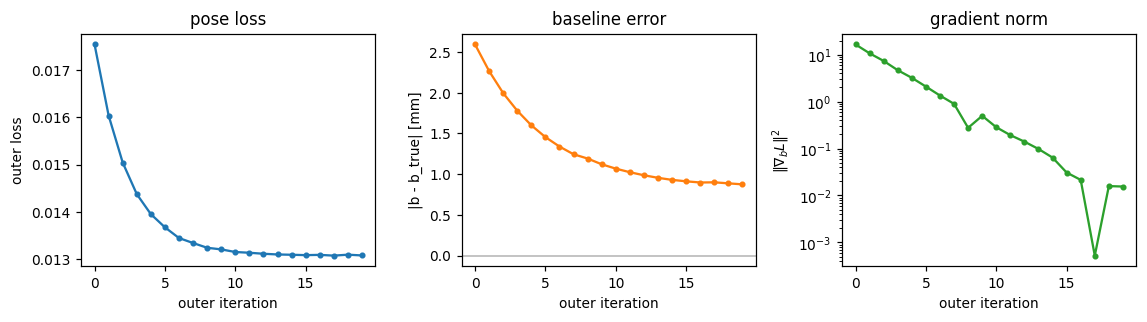

b 初值  : 0.24300 m
b 训练后: 0.24088 m   (真值 0.24000 m)
初始误差: 3.000 mm -> 最终误差: 0.875 mm
外层 loss: 1.7542e-02 -> 1.3079e-02


In [10]:
b_hist = np.array([float(p[0]) for p in hist["params"]])
loss_hist = hist["loss"].to_numpy()
grad_hist = hist["grad_sq"].to_numpy()

fig, axs = plt.subplots(1, 3, figsize=(10.5, 3.0))
axs[0].plot(loss_hist, "o-", ms=3)
axs[0].set(xlabel="outer iteration", ylabel="outer loss", title="pose loss")
axs[1].plot(np.abs(b_hist - sc.cam_gt.b) * 1000, "o-", ms=3, color="tab:orange")
axs[1].axhline(0, color="0.7", lw=1)
axs[1].set(xlabel="outer iteration", ylabel="|b - b_true| [mm]", title="baseline error")
axs[2].semilogy(grad_hist, "o-", ms=3, color="tab:green")
axs[2].set(xlabel="outer iteration", ylabel=r"$\|\nabla_b L\|^2$", title="gradient norm")
plt.tight_layout(); plt.show()

print("b 初值  : %.5f m" % (sc.cam_gt.b + 0.003))
print("b 训练后: %.5f m   (真值 %.5f m)" % (b_hist[-1], sc.cam_gt.b))
print("初始误差: %.3f mm -> 最终误差: %.3f mm" % (
    3.0, abs(b_hist[-1] - sc.cam_gt.b) * 1000))
print("外层 loss: %.4e -> %.4e" % (loss_hist[0], loss_hist[-1]))

三条曲线说明同一件事：**梯度是对的**——`b` 持续靠近真值，loss 和 $\|\nabla_b L\|^2$ 同步下降。
论文里这张图是 Fig. 4（50 runs × 20 poses 的 50 条轨迹），形状与这里单条轨迹一致。

> 为什么不能只对局部解求导？[复现报告](../../report/reproduction.md) 里的对照实验：
> 从随机初始化出发的局部解会给错梯度，标定误差停在 0.33 m（论文 0.11 m）；
> SDPR 不需要好的初始化，因为它解的是凸松弛、并带全局最优证书。

## 7. 从「训练一个标量」到「训练一个网络」：论文 §VI-C 的视觉管线

上面的 `b` 只是一个标量，但**训练循环的形状完全一样**。论文 §VI-C 的 In-The-Dark
实验把「参数」换成 VGG16 + 两个 UNet 解码器的权重：

```
双目图像 (B×12×384×512)
   └─ VGG16 (ImageNet, 截到 conv5_3) + 两个 UNet 解码器
        ├─ 关键点 logits (B×1×384×512) ─→ 16×16 窗口 softmax ─→ 768 个 2D 关键点
        ├─ 得分        (B×1×384×512)
        └─ 描述子 960 维 = conv2–conv5 四级特征拼接（64+128+256+512=960，L2 归一化）
   └─ 描述子匹配（源 768 × 目标 196,608 个像素）+ 得分 → 标量权重 w
   └─ 双目逆投影 → 3D 点 m_k, y_k + 协方差权重 W_k
   └─ 组装 13×13 Q（每个点一对）→ SDPRLayer → 相对位姿 T
   └─ pose loss（平面 x/y/heading + 关键点重投影）→ backward 穿过 SDPR → VGG16/UNet
```

关键点：**SDPR 层本身没有可学习参数**；训练的是它前面的前端。梯度路径是
`pose loss → x* → Q → 关键点/权重 → 前端权重`，中间那一步正是第 5 节验证的隐式微分。
论文用 10 万训练 + 2 万验证样本，前 10 个 epoch 只算关键点损失（warm-up），
之后才加位姿损失；数据是 UTIAS In-The-Dark 夜间双目数据集（39 条 260 m 路线、约 30 小时，
Grizzly 机器人 + Bumblebee XB3 双目，需从 ASRL 数据集网站下载）。

![SDPR 训练管线](../assets/sdpr_pipeline.png)

上图把两条路线画在一起：上半部分是论文 §VI-C 的真实视觉管线（VGG16+UNet → 关键点/描述子/权重 → Q → SDPR → 位姿），下半部分是本节和下一节能真跑的最小版本。两者的训练循环完全相同，区别只是「Q 从哪里来」。

下面用一个**极小的可学习前端**演示梯度确实能穿过层回到网络参数（不训练，只看梯度）：

In [11]:
# 一个「假前端」：8 维特征 -> 3 维修正量，作用在目标三维点上。
# 真实论文里这个前端是 VGG16+UNet；这里只验证梯度路径。
torch.manual_seed(0)
head = torch.nn.Linear(8, 3, bias=False).double()
feat = torch.randn(B, N, 8)                        # 每个点 8 维特征（模拟网络中间层输出）
trg_net = trg.clone()
trg_net[:, :3, :] = trg_net[:, :3, :] + head(feat).transpose(1, 2) * 0.01

T_net, _ = est(src, trg_net, weights, W, return_loss=True)
C = T_net[:, :3, :3]
r = C.mT.bmm(-T_net[:, :3, [3]])
loss = st.get_outer_loss(r, C, r_p0s, C_p0s)
loss.backward()

print("loss = %.6f" % float(loss))
print("head.weight.grad 形状:", tuple(head.weight.grad.shape))
print("head.weight.grad 范数: %.3e  (非 0 即梯度穿过了 SDPR 层)" % float(head.weight.grad.norm()))

loss = 0.047777
head.weight.grad 形状: (3, 8)
head.weight.grad 范数: 1.787e-01  (非 0 即梯度穿过了 SDPR 层)


`head.weight.grad` 非零，说明 `loss → T → x* → Q → 目标点 → head` 这条链是通的；
把 `head` 换成 VGG16+UNet，就是论文 §VI-C 的训练。真实训练还多两件事：

1. **匹配是软的**：描述子点积 + softmax 得到「伪目标点」，梯度可以穿过匹配；
2. **权重是矩阵的**：每个点除了标量置信度，还有 3×3 逆协方差 $W_k$，也参与 Q 的组装。

这一节的前向网络、数据集和论文配置在[完整报告](../../report/sdpr_forward_network_dataset.md)里有更详细的版本
（VGG16+两个 UNet 解码器、960 维描述子、匹配与矩阵权重、In-The-Dark 数据集来源）；
本仓库的 `src/train_eval.py` 是一个更接近真实规模的迷你版（V-JEPA 特征 → 边上的相对旋转头
→ SDPR 旋转同步 → 全局位姿损失，`e2e` / `twostage` / `direct` 三种训练方式），
想跑「网络端到端」可以直接从那里开始。

## 8. 结果对照、局限与复现命令

| 项目 | 论文 | 本仓库独立复现 |
|-|-|-|
| 最终基线误差 | 3.45e-4 m | 4.1e-4 m（50 runs × 20 poses） |
| 外层 loss | 9.86e-3 | 7.5e-3 ~ 1.25e-2 |
| 松弛紧性 | 秩 1、证书成立 | 108,420 次内层解 100% rank-1，$H\succeq0$ |
| 随机初始化局部解 | 0.113 m | 0.327–0.338 m（方向一致，量级偏大） |

本 notebook 只复现 §VI-B4 的**单条训练轨迹**（20 步、SCS 后端），用于展示训练机制；
完整复现（50 runs、局部解对照、Jacobian 校验、紧性统计）见 [复现报告](../../report/reproduction.md)。

**局限**

- 这里用 SCS 代替 MOSEK，梯度精度约 0.5%–1%（`h=1e-4` 时）；MOSEK 下论文报告的是 1e-6 量级。
- 没有跑 §VI-C 的 VGG16+UNet 训练（需要 In-The-Dark 数据集和数小时 GPU），
  只验证了梯度路径；真实管线见第 7 节的说明。
- 单 seed、单次运行；曲线形状会随数据/噪声种子略变。

**复现命令**

```bash
conda activate sdpr
cd ~/labs/SDPR/code/sdprlayer && git log -1 --oneline
python -m nbconvert --to notebook --execute --inplace \
  ~/path/to/notebooks/sdpr/sdpr_training_walkthrough.ipynb
```

本 notebook 用到的代码位置：

| 文件 | 作用 |
|-|-|
| `src/sdprlayers/layers/sdprlayer.py` | `SDPRLayer`：cvxpy SDP + diffcp + 隐式微分 |
| `src/sdprlayers/layers/pose_est.py` | `SDPPoseEstimator`：13 维位姿 QCQP 的 Q 组装与读解 |
| `src/sdprlayers/utils/stereo_tuner.py` | `StereoCamera`、`get_outer_loss`、`tune_stereo_params_sdpr` |
| `_scripts/stereo_cal.py` | 论文 §VI-B4 的数据生成与实验脚本 |